# 01 · Target transform

**Idea:** the target spans 2–768 and errors look multiplicative (notebook 00). Training on log(y)
makes the loss treat "predicted 20 instead of 2" like "predicted 2000 instead of 200", which should
lower MAPE. We compare four targets for each model:

- `none`: raw capacity (as in the old pipeline)
- `log`: log(y)
- `sqrt`: √y, between raw and log
- `rank`: normal scores of the training ranks (inverted by interpolation); aimed at ranking

Predictions in transformed space are clipped to the training range before mapping back, so a linear
model can't produce huge values through exp(). The models use fixed, reasonable settings (no tuning)
so that only the target changes.

In [1]:
import os
import sys
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(".."))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import BayesianRidge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from cofreg import plots
from cofreg.cv import load_oof, repeated_folds, run_many
from cofreg.data import RESULTS_DIR, load_data, load_features
from cofreg.models import TargetTransformed

plots.style()
EXPERIMENT = "01_target_transform"
y = load_data().capacity_max.to_numpy()
repeats = repeated_folds(y)
X_brr = load_features("descriptor", "ecfp", "estate", "functional_groups")
X_rf = load_features("estate", "functional_groups")

In [2]:
BASE = {
    "brr": (lambda: make_pipeline(StandardScaler(), BayesianRidge()), X_brr, "descriptor+ecfp+estate+fg"),
    "rf": (lambda: RandomForestRegressor(500, min_samples_leaf=2, max_features=0.3, random_state=0, n_jobs=1), X_rf, "estate+fg"),
    "catboost": (lambda: CatBoostRegressor(iterations=500, depth=4, learning_rate=0.03, verbose=0, thread_count=1, random_seed=0), X_rf, "estate+fg"),
}
configs = [
    (f"{name}_{t}", TargetTransformed(make(), t), X, feats)
    for name, (make, X, feats) in BASE.items()
    for t in ["none", "sqrt", "log", "rank"]
]
summary = run_many(configs, y, repeats, EXPERIMENT)
summary["transform"] = summary.model.str.rsplit("_", n=1).str[1]
summary.to_csv(os.path.join(RESULTS_DIR, EXPERIMENT, "summary.csv"), index=False)
summary[["model", "mape_mean", "pa_mean", "pa_std", "rmse_mean", "male_mean", "mape_ge20_mean", "r2_mean"]].round(3)

brr_none                                      MAPE 3.655±0.080  PA 0.666±0.009  RMSE 177.8±2.6  MALE 0.786  (1.5s)
brr_sqrt                                      MAPE 2.884±0.098  PA 0.668±0.012  RMSE 181.1±2.7  MALE 0.769  (0.1s)
brr_log                                       MAPE 2.201±0.091  PA 0.661±0.011  RMSE 197.2±2.1  MALE 0.812  (0.1s)


brr_rank                                      MAPE 3.208±0.089  PA 0.667±0.010  RMSE 179.5±2.4  MALE 0.787  (0.1s)


rf_none                                       MAPE 2.757±0.076  PA 0.671±0.008  RMSE 177.8±2.6  MALE 0.743  (2.0s)


rf_sqrt                                       MAPE 1.952±0.077  PA 0.679±0.009  RMSE 178.4±3.4  MALE 0.691  (2.0s)


rf_log                                        MAPE 1.397±0.070  PA 0.677±0.008  RMSE 187.0±3.1  MALE 0.688  (2.0s)


...

catboost_none                                 MAPE 2.828±0.252  PA 0.648±0.008  RMSE 188.6±3.2  MALE 0.763  (1.2s)


catboost_sqrt                                 MAPE 2.026±0.199  PA 0.657±0.009  RMSE 187.7±3.9  MALE 0.709  (1.0s)


catboost_log                                  MAPE 1.459±0.156  PA 0.665±0.012  RMSE 189.7±5.8  MALE 0.702  (1.0s)


catboost_rank                                 MAPE 2.001±0.193  PA 0.655±0.008  RMSE 189.3±4.6  MALE 0.710  (1.0s)


,model,mape_mean,pa_mean,pa_std,rmse_mean,male_mean,mape_ge20_mean,r2_mean
0,brr_none,3.655,0.666,0.009,177.788,0.786,0.850,0.174
1,brr_sqrt,2.884,0.668,0.012,181.082,0.769,0.743,0.144
2,brr_log,2.201,0.661,0.011,197.163,0.812,0.667,-0.015
3,brr_rank,3.208,0.667,0.010,179.523,0.787,0.798,0.158
4,rf_none,2.757,0.671,0.008,177.761,0.743,0.838,0.175
5,rf_sqrt,1.952,0.679,0.009,178.395,0.691,0.698,0.169
6,rf_log,1.397,0.677,0.008,187.035,0.688,0.606,0.086
7,rf_rank,1.945,0.673,0.011,179.113,0.687,0.745,0.162
8,catboost_none,2.828,0.648,0.008,188.594,0.763,0.878,0.071
9,catboost_sqrt,2.026,0.657,0.009,187.709,0.709,0.762,0.080


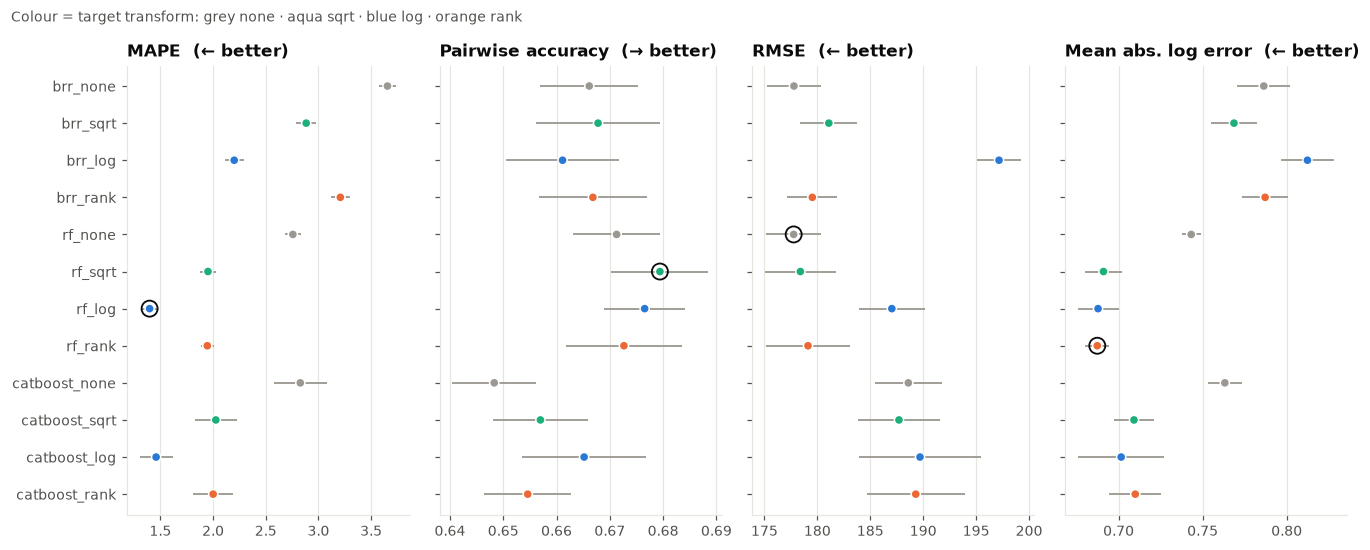

In [3]:
colors = {"none": plots.GRAY, "sqrt": plots.AQUA, "log": plots.BLUE, "rank": plots.ORANGE}
fig = plots.metric_dots(summary, highlight={m: colors[t] for m, t in zip(summary["model"], summary["transform"])})
fig.suptitle("Colour = target transform: grey none · aqua sqrt · blue log · orange rank", x=0.01, ha="left", fontsize=9, color=plots.INK_2)
fig.tight_layout()

## What changes in the predictions

Random forest, raw vs log target. With the raw target the forest averages capacities, so small
values are pulled up to ~100. With log it averages log-capacities (a geometric mean), so it predicts
small values much better, at the cost of larger absolute errors for the highest capacities.

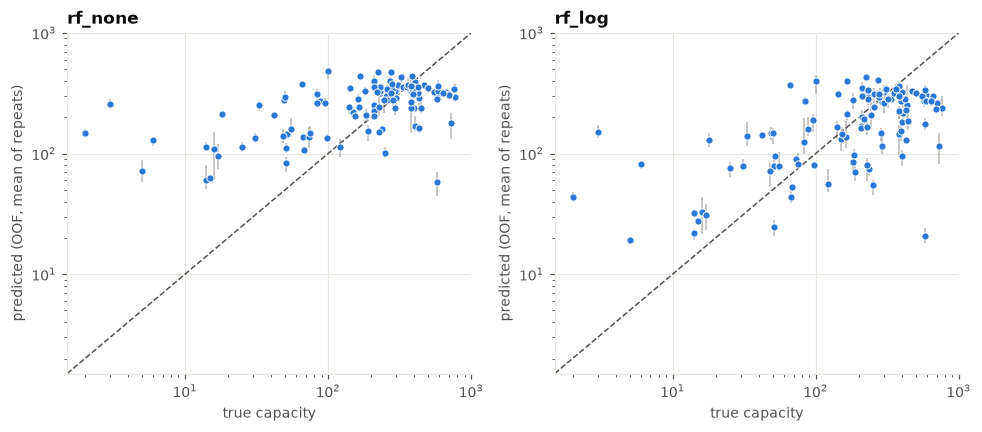

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, name in zip(axes, ["rf_none", "rf_log"]):
    plots.pred_vs_true(y, load_oof(EXPERIMENT, name)[1], name, ax=ax)
fig.tight_layout()

## Takeaways

- **log target halves MAPE** for every model (RF 2.76 → 1.40, CatBoost 2.83 → 1.46, BRR 3.66 → 2.20).
  For the tree models it also lowers MALE (RF 0.743 → 0.688).
- Pairwise accuracy barely moves (all changes ≈ 0.01, about the noise level across repeats).
- RMSE gets 5–10% worse with log, because the highest capacities are under-predicted. sqrt keeps RMSE
  and still cuts MAPE by about a third, so it is a reasonable compromise if RMSE matters.
- BRR does worse on log than the trees: a linear model in log space extrapolates badly.
- The rank target doesn't improve ranking: pairwise accuracy is limited by the features, not the loss.
- **From here on the default is the log target.**